# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) — начальные веса (w0[0] — свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state
    

    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)

        if self.gd_type not in ('full', 'stochastic'):
            raise ValueError("gd_type должен быть 'full' или 'stochastic'")

        N = X.shape[0]
        X = np.hstack([np.ones((N, 1)), X])

        if self.w0 is None:
            self.w = np.zeros(X.shape[1])
        else:
            self.w = np.array(self.w0, dtype=float)  # копия, чтобы не менять w0

        for step in range(self.max_iter):
            if self.gd_type == 'stochastic':
                idx = rng.choice(N, size=min(self.batch_size, N), replace=False)
                Xb, yb = X[idx], y[idx]
            else:
                Xb, yb = X, y

            self.loss_history.append(self.calc_loss(X, y))
            w_prev = self.w.copy()
            self.w = self.w - self.eta * self.calc_gradient(Xb, yb)

            if np.linalg.norm(self.w - w_prev) < self.tolerance:
                break

        return self

    def sigmoid(self, z):
        # ваше решение здесь
        return 1/(1 + np.exp(-z))

    def _add_ones(self, X):
        X = np.asarray(X, dtype=float)
        return np.hstack([np.ones((X.shape[0], 1)), X])

    def _proba1(self, X_ext):
        return self.sigmoid(X_ext @ self.w)

    def predict_proba(self, X):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N, 2)
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        p1 = self._proba1(self._add_ones(X))
        return np.column_stack([1 - p1, p1])

    def predict(self, X, threshold=0.5):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N) из 0 и 1
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        return (self.predict_proba(X)[:, 1] > threshold).astype(int)

    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) — градиент log-loss по self.w
        """
        # ваше решение здесь
        N = X.shape[0]
        probas = self._proba1(X)
        return 1 / N * (X.T @ (probas - y))

    def calc_loss(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float — значение log-loss при текущих self.w
        """
        # ваше решение здесь
        probas = np.clip(self._proba1(X), 1e-12, 1 - 1e-12)
        N = X.shape[0]
        return - (1 / N) * (y @ np.log(probas) + (1 - y) @ np.log(1 - probas))

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 1.44e-10


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

In [6]:
model1 = LogReg()
model2 = LogReg(gd_type = 'stochastic')

model1.fit(X_train, y_train)
model2.fit(X_train, y_train)


,gd_type,'stochastic'
,tolerance,0.0001
,max_iter,1000
,w0,None
,eta,0.01
,batch_size,32
,random_state,42


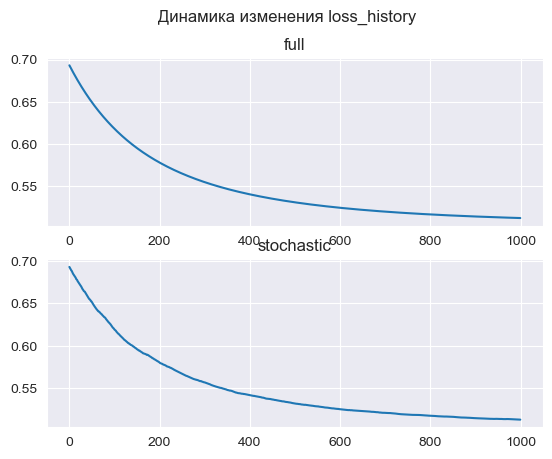

In [7]:
fig, axs = plt.subplots(2)
fig.suptitle('Динамика изменения loss_history')
axs[0].set_title('full')
axs[0].plot(model1.loss_history)

axs[1].set_title('stochastic')
axs[1].plot(model2.loss_history)

*Ваши выводы здесь.*

Судя по графикам, обе модели обучилались *1000 итераций*, остановились по `max_iter`. Отличий по графикам особо не видно, однако, если присмотреться, можно увидеть, что у стохастического варианта график не монотонный. Стохастический градиентный спуск реже будет останавливаться по tolerance, так как считает градиент только по определенному количеству элементов => информация, которая вносится в веса на каждом шаге, ограниченная и шумная => сложнее сойтись. 

Full gd просматривает на каждом шаге весь датасет, а stochastic только batch_size элементов

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

============ eta = 0.001 ============
Число итераций: 1000
Финальное значение лосса: 0.6181405328326297

============ eta = 0.01 ============
Число итераций: 1000
Финальное значение лосса: 0.512450932659742

============ eta = 0.1 ============
Число итераций: 465
Финальное значение лосса: 0.5057620718369386

============ eta = 1 ============
Число итераций: 70
Финальное значение лосса: 0.505756667817523

============ eta = 10 ============
Число итераций: 1000
Финальное значение лосса: 0.9458067848464206



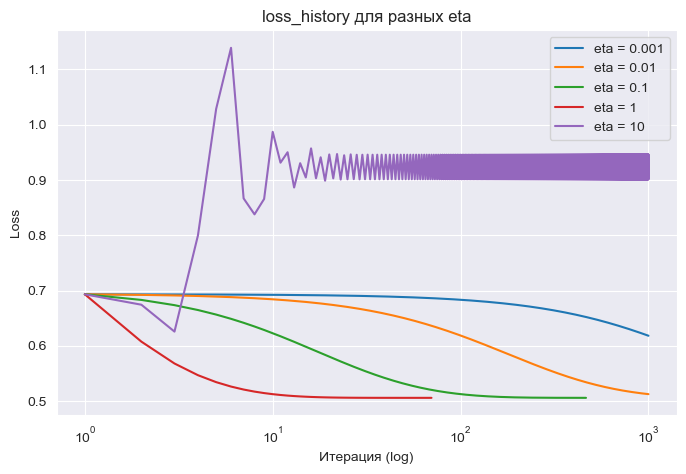

In [8]:
# ваше решение здесь

etas = [1e-3, 1e-2, 1e-1, 1, 10]
histories = {}

for eta in etas:
    print(f'============ eta = {eta} ============')
    temp_model = LogReg(eta=eta)
    temp_model.fit(X_train, y_train)
    histories[eta] = temp_model.loss_history
    
    print(f'Число итераций: {len(temp_model.loss_history)}')
    print(f'Финальное значение лосса: {temp_model.loss_history[-1]}')
    print()


# графики loss_history для разных eta (ось x — логарифмическая)
plt.figure(figsize=(8, 5))
for eta, hist in histories.items():
    plt.plot(np.arange(1, len(hist) + 1), hist, label=f'eta = {eta}')
plt.xscale('log')
plt.xlabel('Итерация (log)')
plt.ylabel('Loss')
plt.title('loss_history для разных eta')
plt.legend()
plt.show()


*Ваши выводы здесь.*
Коэффициент при градиенте в гд напрямую влияет на качество и скорость сходимости: модели с слишком маленьким `eta` (0.001, 0.01) не успевают сойтись за 1000 шагов, тогда как модель с слишком большим параметром вообще не сходится. Оптимальным вариантом оказались `eta = 0.1` и `eta = 0.01`, они обеспечивают и скорость за счет большого вкалада градиентом на каждом шаге и качество за счет того, что шаги по функции потерь не такие резкие. 

Стоит заметить, что это результаты для полного gd. В стохастическом варианте стоит использовать шаг поменьше, так как в градиент может попасть много шумной информации

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [9]:
# ваше решение здесь
model_from_sklearn = LogisticRegression()
model_from_sklearn.fit(X_train, y_train)

model_from_scratch_1 = LogReg()
model_from_scratch_2 = LogReg(gd_type= 'stochastic')

model_from_scratch_1.fit(X_train, y_train)
model_from_scratch_2.fit(X_train, y_train)

,gd_type,'stochastic'
,tolerance,0.0001
,max_iter,1000
,w0,None
,eta,0.01
,batch_size,32
,random_state,42


In [10]:
results = pd.DataFrame(columns=['model', 'ROC AUC', 'Accuracy'])

models = [model_from_sklearn, model_from_scratch_1, model_from_scratch_2]
for i in range(len(models)):
    roc_auc = metrics.roc_auc_score(y_test, models[i].predict_proba(X_test)[:, 1])
    accuracy = metrics.accuracy_score(y_test, models[i].predict(X_test))
    if i == 0:
        name = 'sklearn'
    elif i == 1:
        name = 'full_gd'
    else:
        name = 'stochastic'
    
    curr_res = pd.Series([name, roc_auc, accuracy], index=results.columns)
    
    results.loc[i] = curr_res

results

,model,ROC AUC,Accuracy
0,sklearn,0.838676,0.7765
1,full_gd,0.838787,0.782
2,stochastic,0.838115,0.7825


In [11]:
print(f'Веса модели из sklearn: {model_from_sklearn.coef_}')
print(f'Свободный коэф модели из sklearn: {model_from_sklearn.intercept_}')
print()
print(f'Веса модели full_gd: {model_from_scratch_1.w[1:]}')
print(f'Свободный коэф модели из full_gd: {model_from_scratch_1.w[0]}')
print()
print(f'Веса модели stochastic: {model_from_scratch_2.w[1:]}')
print(f'Свободный коэф модели из stochastic: {model_from_scratch_2.w[0]}')
print()


Веса модели из sklearn: [[ 0.00274083  0.00903929 -0.72269022 -0.26233471  0.01658833 -0.01148751
   0.00558689  0.05718778 -0.00123946 -0.00767111  0.74943677  0.5761082
  -0.28208242 -0.02879039 -0.25441802 -0.72874111  0.00533303 -0.01535677
  -0.0046315   0.01664752]]
Свободный коэф модели из sklearn: [-0.02187979]

Веса модели full_gd: [ 0.00607575  0.00696253 -0.54716973 -0.14453616  0.01248676 -0.00632463
  0.00081432  0.03908404 -0.00242458 -0.0012612   0.57352323  0.5062534
 -0.20739624 -0.01978962 -0.16879394 -0.54744707  0.00410176 -0.01230446
 -0.0056792   0.00813279]
Свободный коэф модели из full_gd: -0.002114450978901871

Веса модели stochastic: [ 2.83484948e-02 -3.17648163e-03 -5.44235395e-01 -1.45952048e-01
  1.18521285e-02 -1.23460651e-02 -1.61889579e-02  3.47639916e-02
  5.90615831e-03  2.90289650e-04  5.71195175e-01  5.06645546e-01
 -2.03571659e-01 -3.55582941e-02 -1.71703790e-01 -5.40303650e-01
 -2.28587728e-02 -9.37155372e-03 -1.23245622e-02 -3.71192616e-03]
Свобод

*Ваши выводы здесь.*

Веса моделей не близки друг к другу. Метрики отличаются, но не факт, что эти различия можно считать статзначимыми.  Что касается различий между нашей имплементацией и sklearnовской, то во второй используется регуляризация по умолчанию. К тому же, оптимизаторы (солверы) - это численные методы, а не градиентные методы оптимизации, как у нас. 

Чтобы решать ту же задачу, надо отключить регуляризацию `penalty = 'none'`

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [12]:
df = pd.read_csv('https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv')

print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [13]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4547, 12)  Test: (1950, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [14]:
# ваше решение здесь
print(f'Пропуски по столбцам:\n{df.isna().sum()}')
print()
print(f'Число полных дубликатов: {df.duplicated().sum()}')
print()
print(f'Доля класса 1 в train: {y_train.mean()}')
print(f'Доля класса 1 в test: {y_test.mean()}')
print()

y_const = np.zeros(len(y_test))
print(f'Accuracy константной модели (всегда класс 0): {metrics.accuracy_score(y_test, y_const)}')

pipe = make_pipeline(StandardScaler(), LogisticRegression())
pipe.fit(X_train, y_train)
print(f'Accuracy логистической регрессии: {metrics.accuracy_score(y_test, pipe.predict(X_test))}')

Пропуски по столбцам:
fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
is_red                  0
target                  0
dtype: int64

Число полных дубликатов: 1177

Доля класса 1 в train: 0.19661315152848033
Доля класса 1 в test: 0.19641025641025642

Accuracy константной модели (всегда класс 0): 0.8035897435897436
Accuracy логистической регрессии: 0.82


*Ваши выводы здесь.*

Пропусков в данных нет. Полных дубликатов 1177, но удалять их в этой задаче, скорее всего, не нужно: в данных нет id вина, а физико-химические показатели измерены с ограниченной точностью, поэтому у разных вин вполне могут совпасть все признаки. Это не ошибка записи, а реальные объекты, и если их удалить, то мы исказим реальное распределение данных.

Доля класса 1 в train и test почти одинаковая: `0.1966` и `0.1964`. `stratify=y` нужен, чтобы при разбиении сохранилась пропорция классов в обеих выборках. Иначе из-за случайности (класс 1 редкий) в test могло бы оказаться заметно больше или меньше хороших вин, и метрики стало бы сложнее сравнивать.

Константная модель, которая всегда отвечает «не хорошее вино», получает accuracy `0.8036`, а логистическая регрессия `0.8200`. Разница всего около 1.6 процентных пункта. Accuracy плохо подходит для этой задачи, потому что классы несбалансированы: модель, которая вообще не находит ни одного хорошего вина, уже получает высокий accuracy просто за счет преобладающего класса.


### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP = 98, TN = 1501, FP = 66, FN = 285

Матрица ошибок из sklearn:
[[1501   66]
 [ 285   98]]
Совпадает с нашей: True


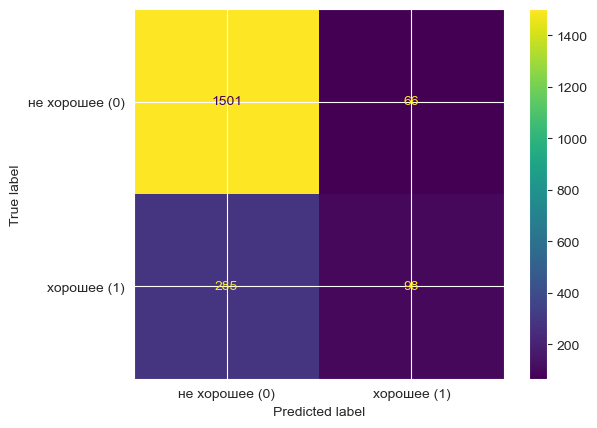

In [15]:
# ваше решение здесь
y_pred = pipe.predict(X_test)
y_true = np.asarray(y_test)

TP = np.sum((y_pred == 1) & (y_true == 1))
TN = np.sum((y_pred == 0) & (y_true == 0))
FP = np.sum((y_pred == 1) & (y_true == 0))
FN = np.sum((y_pred == 0) & (y_true == 1))
print(f'TP = {TP}, TN = {TN}, FP = {FP}, FN = {FN}')
print()

cm = metrics.confusion_matrix(y_true, y_pred)
print(f'Матрица ошибок из sklearn:\n{cm}')
print(f'Совпадает с нашей: {np.array_equal(cm, np.array([[TN, FP], [FN, TP]]))}')

metrics.ConfusionMatrixDisplay(cm, display_labels=['не хорошее (0)', 'хорошее (1)']).plot()
plt.show()

*Ваши выводы здесь.*

Наши подсчеты вручную (`TP = 98`, `TN = 1501`, `FP = 66`, `FN = 285`) совпали с `metrics.confusion_matrix`.

В терминах сценария: FP - это модель посчитала вино хорошим, а на самом деле оно посредственное. Такое вино попадет в подборку и клиент будет разочарован. FN - это хорошее вино, которое модель пропустила, из-за чего подборка получается более скудной.

Чаще встречается FN: 285 против 66. Модель очень осторожно предсказывает класс 1 (всего 164 вина названы хорошими, а настоящих хороших вин 383), и из них находит лишь 98, то есть около четверти. Это следствие дисбаланса классов: при пороге 0.5 модели выгоднее чаще отвечать «не хорошее».


### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [16]:
# ваше решение здесь
precision = TP / (TP + FP)
recall = TP / (TP + FN)

def f_beta(precision, recall, beta):
    return (1 + beta**2) * precision * recall / (beta**2 * precision + recall)

f1 = f_beta(precision, recall, 1)
f05 = f_beta(precision, recall, 0.5)
f2 = f_beta(precision, recall, 2)

print('Посчитано вручную:')
print(f'precision = {precision}')
print(f'recall = {recall}')
print(f'F1 = {f1}')
print(f'F0.5 = {f05}')
print(f'F2 = {f2}')
print()

print('Из sklearn.metrics:')
print(f'precision = {metrics.precision_score(y_true, y_pred)}')
print(f'recall = {metrics.recall_score(y_true, y_pred)}')
print(f'F1 = {metrics.fbeta_score(y_true, y_pred, beta=1)}')
print(f'F0.5 = {metrics.fbeta_score(y_true, y_pred, beta=0.5)}')
print(f'F2 = {metrics.fbeta_score(y_true, y_pred, beta=2)}')

Посчитано вручную:
precision = 0.5975609756097561
recall = 0.2558746736292428
F1 = 0.35831809872029247
F0.5 = 0.47160731472569783
F2 = 0.28891509433962265

Из sklearn.metrics:
precision = 0.5975609756097561
recall = 0.2558746736292428
F1 = 0.3583180987202925
F0.5 = 0.4716073147256978
F2 = 0.28891509433962265


*Ваши выводы здесь.*

Значения, посчитанные по формулам, совпали с `sklearn` (`precision = 0.598`, `recall = 0.256`, `F1 = 0.358`, `F0.5 = 0.472`, `F2 = 0.289`).

В $F_{0.5}$ больше ценится precision, а в $F_2$ - recall (в $F_2$ recall весит в 4 раза больше precision).

Если подписчики очень болезненно реагируют на посредственные вина, то лучше взять $F_{0.5}$: нам важнее, чтобы то, что мы рекомендуем, действительно было хорошим (меньше FP). Если сервис позиционируется как «самая широкая подборка хороших вин», то лучше $F_2$: важнее не пропустить хорошие вина (меньше FN).

P.s. клод красиво оформил вывод


### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

Число итераций нашего GD: 3765



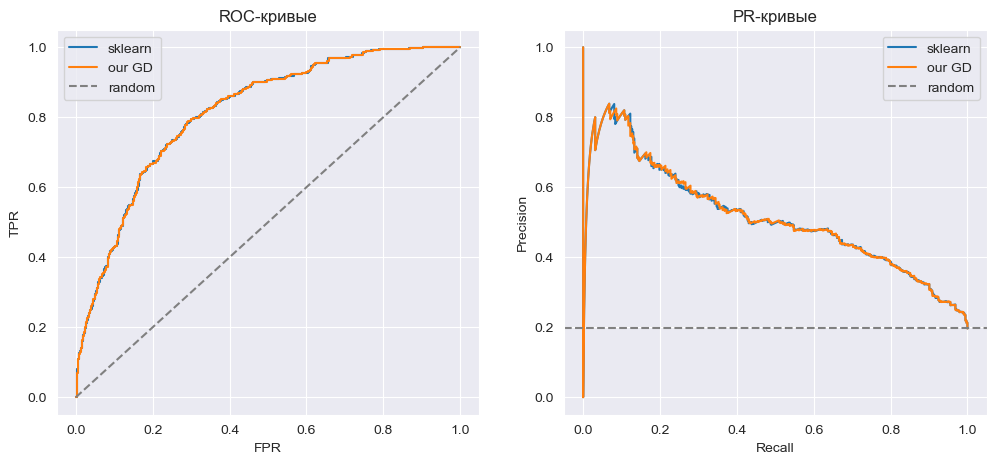

     model   ROC AUC    PR AUC
0  sklearn  0.813537  0.512115
1   our GD  0.813512  0.512230

PR AUC случайной модели (доля класса 1 в test): 0.19641025641025642

ROC AUC исходных p: 0.8135367009852357
ROC AUC для 10 * p: 0.8135367009852357
ROC AUC для p^3: 0.8135367009852357
ROC AUC для logit(p): 0.8135367009852357
ROC AUC для -p: 0.18646329901476436

ROC AUC для предсказанных меток: 0.6068779877399565


In [ ]:
# ваше решение здесь
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

model_gd = LogReg(gd_type='full', eta=1, max_iter=10000, tolerance=1e-6)
model_gd.fit(X_train_sc, y_train)
print(f'Число итераций нашего GD: {len(model_gd.loss_history)}')
print()

scores = {
    'sklearn': pipe.predict_proba(X_test)[:, 1],
    'our GD': model_gd.predict_proba(X_test_sc)[:, 1],
}

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for name, score in scores.items():
    fpr, tpr, _ = metrics.roc_curve(y_true, score)
    axs[0].plot(fpr, tpr, label=name)

    prec, rec, _ = metrics.precision_recall_curve(y_true, score)
    axs[1].plot(rec, prec, label=name)

axs[0].plot([0, 1], [0, 1], '--', color='gray', label='random')
axs[0].set_title('ROC-кривые')
axs[0].set_xlabel('FPR')
axs[0].set_ylabel('TPR')
axs[0].legend()

axs[1].axhline(y_true.mean(), linestyle='--', color='gray', label='random')
axs[1].set_title('PR-кривые')
axs[1].set_xlabel('Recall')
axs[1].set_ylabel('Precision')
axs[1].legend()
plt.show()

auc_table = pd.DataFrame({
    'model': list(scores),
    'ROC AUC': [metrics.roc_auc_score(y_true, s) for s in scores.values()],
    'PR AUC': [metrics.average_precision_score(y_true, s) for s in scores.values()],
})
print(auc_table)
print()
print(f'PR AUC случайной модели (доля класса 1 в test): {y_true.mean()}')
print()

p = scores['sklearn']
transformed = {'10 * p': 10 * p, 'p^3': p**3, 'logit(p)': np.log(p / (1 - p)), '-p': -p}
print(f'ROC AUC исходных p: {metrics.roc_auc_score(y_true, p)}')
for name, s in transformed.items():
    print(f'ROC AUC для {name}: {metrics.roc_auc_score(y_true, s)}')
print()
print(f'ROC AUC для предсказанных меток: {metrics.roc_auc_score(y_true, y_pred)}')
# P.s. клод помог оформить графики и вывод

*Ваши выводы здесь.*

Обе модели получились практически одинаковыми: ROC-AUC `0.8135` у обеих (разница в пятом знаке), PR-AUC `0.5121` у sklearn и `0.5122` у нашего GD. Формально ранжирование по метрикам разное (по ROC-AUC чуть выше sklearn, по PR-AUC чуть выше наш GD), но эта разница ничтожная, так что по сути модели одинаково хороши. Для этого нашему GD пришлось подобрать `eta = 1` и около 3800 итераций (`tolerance = 1e-6`), чтобы он сошелся.

PR-AUC случайной модели равен доле класса 1 в тесте, то есть `0.196`, а не 0.5. У ROC-кривой случайной модели TPR = FPR, поэтому AUC = 0.5 вне зависимости от баланса классов. А у PR-кривой случайная модель на любом уровне recall дает precision, равный доле положительного класса, поэтому у несбалансированной выборки такая линия лежит намного ниже.

ROC-AUC для $10 \cdot p$, $p^3$ и $\log\frac{p}{1-p}$ получился точно таким же, как для исходных $p$. Эти преобразования монотонно возрастают и не меняют порядок объектов, а ROC-AUC зависит только от ранжирования объектов по оценке. А для $-p$ порядок обратный, поэтому AUC стал `1 - 0.8135 = 0.1865`.

Если подать в `roc_auc_score` предсказанные метки вместо вероятностей, то получится `0.607`, то есть заметно хуже: у кривой остается всего одна точка (одна пара FPR и TPR), и мы теряем информацию о ранжировании внутри каждого класса.

P.s. клод помог красиво оформить вывод


### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

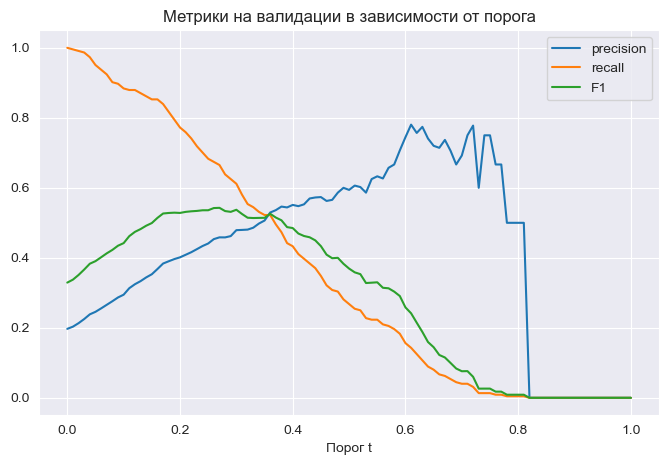

t_F1 = 0.27
t_R = 0.24



,порог,t,precision,recall,F1
0,t = 0.5,0.50,0.597561,0.255875,0.358318
1,t_F1,0.27,0.474708,0.637076,0.544036
2,t_R,0.24,0.434211,0.689295,0.532795


In [18]:
# ваше решение здесь
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE)

pipe_val = make_pipeline(StandardScaler(), LogisticRegression())
pipe_val.fit(X_tr, y_tr)
p_val = pipe_val.predict_proba(X_val)[:, 1]
y_val = np.asarray(y_val)

thresholds = np.linspace(0, 1, 101)
prec_list, rec_list, f1_list = [], [], []
for t in thresholds:
    pred = (p_val >= t).astype(int)
    tp = np.sum((pred == 1) & (y_val == 1))
    fp = np.sum((pred == 1) & (y_val == 0))
    fn = np.sum((pred == 0) & (y_val == 1))
    prec = tp / (tp + fp) if tp + fp > 0 else 0
    rec = tp / (tp + fn)
    prec_list.append(prec)
    rec_list.append(rec)
    f1_list.append(2 * prec * rec / (prec + rec) if prec + rec > 0 else 0)

prec_arr, rec_arr, f1_arr = np.array(prec_list), np.array(rec_list), np.array(f1_list)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, prec_arr, label='precision')
plt.plot(thresholds, rec_arr, label='recall')
plt.plot(thresholds, f1_arr, label='F1')
plt.xlabel('Порог t')
plt.title('Метрики на валидации в зависимости от порога')
plt.legend()
plt.show()

t_f1 = thresholds[np.argmax(f1_arr)]
mask = rec_arr >= 0.7
t_r = thresholds[mask][np.argmax(prec_arr[mask])]
print(f't_F1 = {t_f1}')
print(f't_R = {t_r}')
print()

pipe.fit(X_train, y_train)
p_test = pipe.predict_proba(X_test)[:, 1]

rows = []
for name, t in [('t = 0.5', 0.5), ('t_F1', t_f1), ('t_R', t_r)]:
    pred = (p_test >= t).astype(int)
    rows.append([name, t, metrics.precision_score(y_true, pred), metrics.recall_score(y_true, pred),metrics.f1_score(y_true, pred)])
pd.DataFrame(rows, columns=['порог', 't', 'precision', 'recall', 'F1'])

*Ваши выводы здесь.*

На валидации получились пороги `t_F1 = 0.27` и `t_R = 0.24`. Оба сильно ниже 0.5: из-за дисбаланса классов модель редко дает вероятности выше 0.5 для класса 1, поэтому порог нужно сдвигать вниз. На тесте при пороге 0.5 `recall = 0.256`, а при `t_F1` и `t_R` он поднимается до `0.637` и `0.689`, ценой падения precision (с `0.598` до `0.475` и `0.434`). `F1` при этом вырастает с `0.358` до `0.544` и `0.533`.

Условие `recall >= 0.7` на тесте не выполнилось: при `t_R` получили `0.689`, то есть чуть меньше. Порог, подобранный на валидации, не гарантирует выполнения условия на новых данных, потому что валидация - это конечная выборка, и recall на ней оценивается с шумом (хороших вин там около 200). Тест - другая выборка, поэтому значение recall при том же пороге немного отличается. Кроме того, мы брали порог ровно на границе условия, а значит, любое небольшое отклонение его нарушает.

Для сценария из описания я бы выбрал порог t_R (около 0.24), потому что сервис явно хочет, чтобы в подборку попадало не меньше 70% хороших вин, а при этом нужно максимизировать precision (меньше посредственных вин). Чтобы условие выполнялось надежнее, имеет смысл взять порог с небольшим запасом, например чуть ниже, чтобы recall на валидации был, скажем, 0.72-0.75.


## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [19]:
# ваше решение здесь
def get_metrics(name, model, threshold=0.5):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)
    return { 'model': name, 'accuracy': metrics.accuracy_score(y_test, pred), 'precision': metrics.precision_score(y_test, pred), 'recall': metrics.recall_score(y_test, pred), 'F1': metrics.f1_score(y_test, pred), 'ROC AUC': metrics.roc_auc_score(y_test, proba), 'PR AUC': metrics.average_precision_score(y_test, proba)}

pipe_none = make_pipeline(StandardScaler(), LogisticRegression(class_weight=None))
pipe_balanced = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced'))
pipe_none.fit(X_train, y_train)
pipe_balanced.fit(X_train, y_train)

all_models = {'class_weight=None': (pipe_none, 0.5), 'class_weight=balanced': (pipe_balanced, 0.5)}

# веса классов по формуле из документации: n_samples / (n_classes * n_samples_in_class)
n = len(y_train)
n1 = np.sum(y_train == 1)
n0 = np.sum(y_train == 0)
print(f'Вес класса 0: {n / (2 * n0)}')
print(f'Вес класса 1: {n / (2 * n1)}')

pd.DataFrame([get_metrics(name, m, t) for name, (m, t) in all_models.items()])

Вес класса 0: 0.622365179304681
Вес класса 1: 2.5430648769574944


,model,accuracy,precision,recall,F1,ROC AUC,PR AUC
0,class_weight=None,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
1,class_weight=balanced,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536


*Ваши выводы здесь.*

При `class_weight='balanced'` вес класса 0 равен `0.622`, а вес класса 1 равен `2.543`. Они считаются по формуле из документации `n_samples / (n_classes * n_samples_in_class)`, то есть редкий класс получает вес больше примерно в 4 раза (во столько же раз он реже встречается).

Заметно изменились accuracy, precision, recall и F1: `recall` вырос с `0.256` до `0.755`, `precision` упал с `0.598` до `0.397`, `F1` вырос с `0.358` до `0.520`, а `accuracy` упал с `0.820` до `0.727`. Почти не изменились ROC-AUC (`0.8135` и `0.8113`) и PR-AUC (`0.512` и `0.501`). Дело в том, что веса классов в основном сдвигают границу решения в сторону редкого класса, то есть модель чаще отвечает «хорошее вино», из-за чего растет recall и падают precision и accuracy. А ROC-AUC и PR-AUC зависят только от ранжирования объектов по вероятности, а оно при этом почти не меняется.


### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [20]:
# ваше решение здесь
from imblearn.pipeline import make_pipeline as make_pipeline_imb
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE), 'NearMiss(2)': NearMiss(version=2), 'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE), 'SMOTE': SMOTE(random_state=RANDOM_STATE)}

for name, sampler in samplers.items():
    pipe_res = make_pipeline_imb(StandardScaler(), sampler, LogisticRegression())
    pipe_res.fit(X_train, y_train)
    all_models[name] = (pipe_res, 0.5)

    # размеры классов после ресемплинга
    _, y_res = sampler.fit_resample(StandardScaler().fit_transform(X_train), y_train)
    print(f'{name}: класс 0 = {np.sum(y_res == 0)}, класс 1 = {np.sum(y_res == 1)}')

order_rows = []
for name, sampler in samplers.items():
    pipe_swap = make_pipeline_imb(sampler, StandardScaler(), LogisticRegression())
    pipe_swap.fit(X_train, y_train)
    order_rows.append(get_metrics(name + ': scaler -> sampler', *all_models[name]))
    order_rows.append(get_metrics(name + ': sampler -> scaler', pipe_swap))
print(pd.DataFrame(order_rows))
print()

pd.DataFrame([get_metrics(name, m, t) for name, (m, t) in all_models.items()])

RandomUnderSampler: класс 0 = 894, класс 1 = 894
NearMiss(2): класс 0 = 894, класс 1 = 894
RandomOverSampler: класс 0 = 3653, класс 1 = 3653
SMOTE: класс 0 = 3653, класс 1 = 3653
                                   model  accuracy  precision    recall  \
0  RandomUnderSampler: scaler -> sampler  0.729744   0.401099  0.762402   
1  RandomUnderSampler: sampler -> scaler  0.729744   0.401099  0.762402   
2         NearMiss(2): scaler -> sampler  0.544103   0.281897  0.853786   
3         NearMiss(2): sampler -> scaler  0.681026   0.351183  0.736292   
4   RandomOverSampler: scaler -> sampler  0.726667   0.397260  0.757180   
5   RandomOverSampler: sampler -> scaler  0.726154   0.396433  0.754569   
6               SMOTE: scaler -> sampler  0.729231   0.399166  0.749347   
7               SMOTE: sampler -> scaler  0.733846   0.404225  0.749347   

         F1   ROC AUC    PR AUC  
0  0.525653  0.809354  0.500791  
1  0.525653  0.809389  0.500528  
2  0.423850  0.739948  0.400108  
3  0.4755

,model,accuracy,precision,recall,F1,ROC AUC,PR AUC
0,class_weight=None,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
1,class_weight=balanced,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536
2,RandomUnderSampler,0.729744,0.401099,0.762402,0.525653,0.809354,0.500791
3,NearMiss(2),0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
4,RandomOverSampler,0.726667,0.397260,0.757180,0.521114,0.811484,0.500225
5,SMOTE,0.729231,0.399166,0.749347,0.520871,0.812465,0.503985


*Ваши выводы здесь.*

После ресемплинга классы стали равными: при undersampling (`RandomUnderSampler` и `NearMiss`) по `894` объекта в каждом классе, при oversampling (`RandomOverSampler` и `SMOTE`) по `3653`.

`make_pipeline` нужен именно из `imblearn`, потому что в обычном `sklearn` пайплайне шаги умеют только `fit/transform`, а ресемплер меняет число объектов (и `y`), у него есть метод `fit_resample`. Пайплайн из `imblearn` применяет ресемплинг только при `fit`, а при `predict` ресемплеры пропускаются. Поэтому тестовая выборка не меняется, а только проходит через масштабирование и модель.

Сначала балансировать весь датасет, а потом разбивать на train и test нельзя: при oversampling копии (или синтетические объекты, похожие на исходные) одного и того же вина могли бы попасть и в train, и в test, то есть произошла бы утечка данных, и метрики были бы завышены. К тому же тест перестал бы отражать реальное распределение классов.

По PR-AUC лучший из ресемплингов - `SMOTE` (`0.504`), худший - `NearMiss(2)` (`0.400`). `NearMiss` выкидывает сразу более 2700 объектов класса 0, причем оставляет только те, которые ближе всего к объектам класса 1, поэтому оставшаяся часть класса 0 уже плохо описывает его реальное распределение и модель дает много FP (`precision = 0.28`). Остальные методы дают очень близкие друг к другу результаты. Ни один из ресемплингов не побил модель без весов по PR-AUC (`0.512`).

Порядок шагов «ресемплинг» и «масштабирование» важен для методов, которые используют расстояния между объектами: `NearMiss` и `SMOTE`. Они ищут ближайших соседей, а расстояния зависят от масштаба признаков. Для `RandomUnderSampler` и `RandomOverSampler` порядок почти не важен: они выбирают объекты случайно, без учета значений признаков, и меняется только то, на каких данных `StandardScaler` считает среднее и std. Проверка это подтверждает: если поменять шаги местами, у `NearMiss` ROC-AUC меняется с `0.740` на `0.755`, а `F1` с `0.424` на `0.476`, у `SMOTE` PR-AUC с `0.504` на `0.509`, а у случайных методов метрики практически не меняются (в третьем-четвертом знаке).


### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

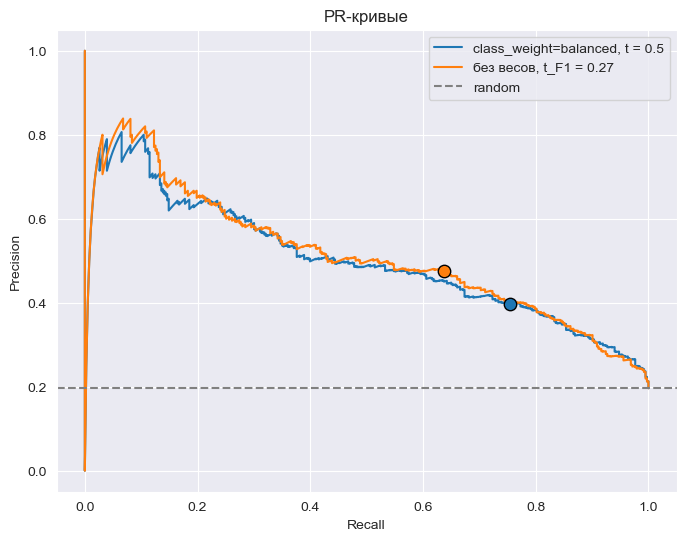

PR AUC balanced: 0.5005364679217181
PR AUC без весов: 0.5121152422168758


,model,accuracy,precision,recall,F1,ROC AUC,PR AUC
0,"balanced, t = 0.5",0.726667,0.396978,0.754569,0.520252,0.811339,0.500536
1,"без весов, t_F1",0.790256,0.474708,0.637076,0.544036,0.813537,0.512115


In [21]:
# ваше решение здесь
p_balanced = pipe_balanced.predict_proba(X_test)[:, 1]
p_none = pipe_none.predict_proba(X_test)[:, 1]

curves = {'class_weight=balanced, t = 0.5': (p_balanced, 0.5), f'без весов, t_F1 = {t_f1}': (p_none, t_f1)}

#P.s. клод оформил график
plt.figure(figsize=(8, 6))
for name, (score, t) in curves.items():
    prec, rec, _ = metrics.precision_recall_curve(y_true, score)
    line, = plt.plot(rec, prec, label=name)

    pred = (score >= t).astype(int)
    plt.scatter(metrics.recall_score(y_true, pred), metrics.precision_score(y_true, pred), color=line.get_color(), s=80, zorder=3, edgecolor='black')

plt.axhline(y_true.mean(), linestyle='--', color='gray', label='random')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR-кривые')
plt.legend()
plt.show()

print(f'PR AUC balanced: {metrics.average_precision_score(y_true, p_balanced)}')
print(f'PR AUC без весов: {metrics.average_precision_score(y_true, p_none)}')
pd.DataFrame([get_metrics('balanced, t = 0.5', pipe_balanced, 0.5), get_metrics('без весов, t_F1', pipe_none, t_f1)])

*Ваши выводы здесь.*

Кривые различаются слабо: PR-AUC `0.501` у модели с весами и `0.512` у модели без весов, а при одинаковом recall precision у модели с весами ниже всего на 0.01-0.02. Выбранные точки лежат на одной и той же практически кривой, но в разных местах: у модели с весами при пороге 0.5 получилось `recall = 0.755` и `precision = 0.397`, а у модели без весов при `t_F1 = 0.27` - `recall = 0.637` и `precision = 0.475`. Значит, взвешивание классов в основном «сдвигает порог»: оно переносит нас в другую точку почти той же PR-кривой, а не делает модель лучше как ранжировщик.


### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [22]:
# ваше решение здесь
all_models['class_weight=None, t_F1'] = (pipe_none, t_f1)
all_models['class_weight=None, t_R'] = (pipe_none, t_r)

final_table = pd.DataFrame([get_metrics(name, m, t) for name, (m, t) in all_models.items()])
final_table

,model,accuracy,precision,recall,F1,ROC AUC,PR AUC
0,class_weight=None,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
1,class_weight=balanced,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536
2,RandomUnderSampler,0.729744,0.401099,0.762402,0.525653,0.809354,0.500791
3,NearMiss(2),0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
4,RandomOverSampler,0.726667,0.397260,0.757180,0.521114,0.811484,0.500225
5,SMOTE,0.729231,0.399166,0.749347,0.520871,0.812465,0.503985
6,"class_weight=None, t_F1",0.790256,0.474708,0.637076,0.544036,0.813537,0.512115
7,"class_weight=None, t_R",0.762564,0.434211,0.689295,0.532795,0.813537,0.512115


*Ваши выводы здесь.*

Лучше всех по ранжированию (ROC-AUC `0.8135`, PR-AUC `0.512`) остается обычная логистическая регрессия без весов и ресемплинга: `class_weight`, `RandomUnderSampler`, `RandomOverSampler` и `SMOTE` дают тот же или чуть худший результат, а `NearMiss(2)` заметно хуже (ROC-AUC `0.740`). Различия между остальными методами в основном определяются тем, в какой точке PR-кривой мы оказались, то есть каким получился порог.

Поэтому я бы предложил сервису модель без весов и ресемплинга (так проще и она не хуже) и порог $t_R \approx 0.24$: при нем `recall = 0.689` и `precision = 0.434`, `F1 = 0.533`. Сервису нужно, чтобы в подборку попадало не меньше 70% хороших вин, а при этом хочется, чтобы посредственных вин было как можно меньше, и порог, подобранный по этому условию на валидации, как раз это делает. Мы видели, что на тесте recall оказался чуть ниже 0.7, поэтому на практике порог лучше взять с небольшим запасом (чуть ниже). Если важнее не условие на recall, а баланс precision и recall, то подойдет $t_{F_1} = 0.27$ с наибольшим `F1 = 0.544`. Модель с `class_weight='balanced'` при пороге 0.5 по сути дает ту же точку на кривой, но порог под условие сервиса в ней подобрать сложнее.


### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [23]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

final_model = pipe_none   # пайплайн без весов, обученный на X_train
final_threshold = t_r     # порог t_R, выбранный на валидации в 2.5

joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(json.dumps({'threshold': float(final_threshold)}))
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)

## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷

ы